In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

In [5]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [6]:
df = df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]

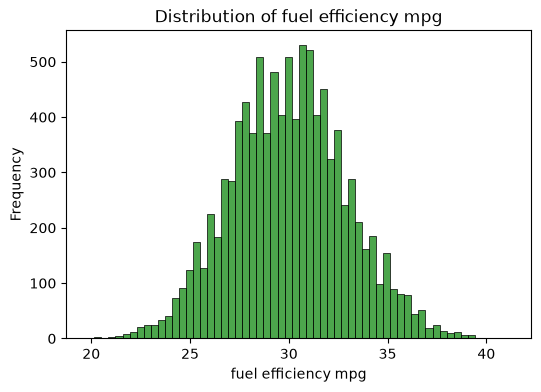

In [12]:
plt.figure(figsize=(6, 4))

sns.histplot(df['fuel_efficiency_mpg'], color='green', alpha=0.7)
plt.ylabel('Frequency')
plt.xlabel('fuel efficiency mpg')
plt.title('Distribution of fuel efficiency mpg')

plt.show()

In [ ]:
#fuel_efficiency_mpg doesn't have a long tail.

In [13]:
df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [14]:
df.horsepower.median()

np.float64(254.0)

In [15]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [19]:
#Filling with 0
dfzeros = df.fillna(0)
df_train0 = dfzeros.iloc[idx[:n_train]]
df_val0 = dfzeros.iloc[idx[n_train:n_train + n_val]]
df_test0 = dfzeros.iloc[idx[n_train + n_val:]]

In [20]:
X_train0 = df_train0.drop(columns=['fuel_efficiency_mpg'])
y_train0 = df_train0['fuel_efficiency_mpg']
X_val0 = df_val0.drop(columns=['fuel_efficiency_mpg'])
y_val0 = df_val0['fuel_efficiency_mpg']

In [18]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [22]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [21]:
wzero, wszeros = train_linear_regression(X_train0,y_train0)

In [24]:
y_pred0 = wzero + X_val0.dot(wszeros)

In [39]:
rmsedf0 = rmse(y_val0, y_pred0)
round(rmsedf0,3)

np.float64(2.205)

In [26]:
#Filling with the mean
df_trainm = df.iloc[idx[:n_train]]
df_valm = df.iloc[idx[n_train:n_train + n_val]]
df_testm = df.iloc[idx[n_train + n_val:]]

In [34]:
hpmean = df_trainm['horsepower'].mean()
df_trainm['horsepower'] = df_trainm['horsepower'].fillna(hpmean)

In [35]:
X_trainm = df_trainm.drop(columns=['fuel_efficiency_mpg'])
y_trainm = df_trainm['fuel_efficiency_mpg']
X_valm = df_valm.drop(columns=['fuel_efficiency_mpg'])
y_valm = df_valm['fuel_efficiency_mpg']

In [36]:
wmean, wsmean = train_linear_regression(X_trainm,y_trainm)

In [37]:
y_predm = wmean + X_valm.dot(wsmean)

In [40]:
rmsedfmean = rmse(y_valm, y_predm)
round(rmsedfmean,3)

np.float64(2.186)

In [41]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [50]:
for r in [0, 0.01, 0.1, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train0, y_train0, r=r)
    y_pred = w_0 + X_val0.dot(w)
    print('%.4f, %.4f' % (r, rmse(y_val0, y_pred)))

0.0000, 2.2053
0.0100, 2.2058
0.1000, 2.2241
0.1000, 2.2241
1.0000, 2.3492
5.0000, 2.4094
10.0000, 2.4195
100.0000, 2.4292


In [56]:
rs = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmselist = []
for r in rs:
    np.random.seed(r)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_train = df_train.fillna(0)
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_val = df_val.fillna(0)
    df_test = df.iloc[idx[n_train + n_val:]]
    df_test = df_test.fillna(0)

    X_train0 = df_train.drop(columns=['fuel_efficiency_mpg'])
    y_train0 = df_train['fuel_efficiency_mpg']
    X_val0 = df_val.drop(columns=['fuel_efficiency_mpg'])
    y_val0 = df_val['fuel_efficiency_mpg']

    wzero, wszeros = train_linear_regression(X_train0,y_train0)
    y_pred0 = wzero + X_val0.dot(wszeros)
    rmsedf0 = rmse(y_val0, y_pred0)
    print('%.f, %.3f' % (r, rmsedf0))
    rmselist.append(rmsedf0)

    

0, 2.239
1, 2.202
2, 2.163
3, 2.204
4, 2.202
5, 2.246
6, 2.270
7, 2.191
8, 2.217
9, 2.207


In [57]:
round(np.std(rmselist),3)

np.float64(0.029)

In [61]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_train = df_train.fillna(0)
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_val = df_val.fillna(0)
df_test = df.iloc[idx[n_train + n_val:]]
df_test = df_test.fillna(0)

df_trainval = pd.concat([df_train, df_val])

X_train0 = df_trainval.drop(columns=['fuel_efficiency_mpg'])
y_train0 = df_trainval['fuel_efficiency_mpg']
X_val0 = df_test.drop(columns=['fuel_efficiency_mpg'])
y_val0 = df_test['fuel_efficiency_mpg']


w_0, w = train_linear_regression_reg(X_train0, y_train0, r=0.001)
y_pred = w_0 + X_val0.dot(w)

round(rmse(y_val0, y_pred),3)




np.float64(2.236)